In [0]:
%pip install networkx

In [0]:
%pip install graphframes

In [0]:
# WILL NOT RUN ON SPARK, ONLY IN NOTEBOOK TO REFERENCE ALGORITHM

import networkx as nx
import statistics
from multiprocessing import Pool, Manager, Lock
import os
import time
from datetime import datetime

# SETUP LOGGING TO FILE
def writeToLogFile(filepath, string):
    print(string)
    with open(filepath, "a") as f:
        f.write(string + "\n")

# IMPORTS EDGELIST FOR PROCESSING
def importEdgelist(gFilepath):
    with open(gFilepath, "rb") as edgelistReader:
        importedEdgelist = nx.read_edgelist(edgelistReader)
    return importedEdgelist

# CONVERTS SEED MAPPING FILE TO SET
def seeds2set(seedMappingsFilepath):
    with open(seedMappingsFilepath, "r") as file:
        seedsSet = {tuple(map(int, line.split())) for line in file}
    return seedsSet

# EXPORTS NEW SEED MAPPINGS TO FILE
def exportSeedMappings(newSeedMappings, newSeedMappingsFilepath):
    with open(newSeedMappingsFilepath, "w") as file:
        for mapping in newSeedMappings:
            file.write(" ".join(map(str, mapping)) + "\n")
    return

# COMPARE GUESSED SEED MAPPINGS TO VERIFIED SEED MAPPINGS
def compareSeedMappings(calculatedMappings, verifiedMappings, log_fp):
    calculatedMappings = set(map(tuple, calculatedMappings))
    verifiedMappings = set(map(tuple, verifiedMappings))
    sharedMappings = calculatedMappings & verifiedMappings
    matchPercent = round((len(sharedMappings) / len(verifiedMappings)) * 100,3)
    msg = f"Calculated Seeds and Verified Seeds are {matchPercent}% matching with {len(sharedMappings)}/{len(verifiedMappings)} matches."
    writeToLogFile(log_fp, msg)
    return

def createSetOfMappedNodes(generatedSeeds, g1):
    nodesInGeneratedSeeds = {pair[0] for pair in generatedSeeds}
    g1NodesAsInts = {int(node) for node in g1.nodes}
    mappedG1nodes = g1NodesAsInts & nodesInGeneratedSeeds
    return mappedG1nodes

# PROCESS A SINGLE NODE
def process_left_node(args):
    leftNode, g1, g2, sharedSeedMappings, lock = args
    similarity = []
    maxScore = 0.0
    nodeOfMaxScore = ''
    likelyMatch = []
    
    with lock:
        currentSeedMappings = set(sharedSeedMappings)
    leftMappedAdj = {neighbor for neighbor in g1.adj[leftNode] if int(neighbor) in {pair[0] for pair in currentSeedMappings}}
    
    for rightNode in g2.nodes:
        rightMappedAdj = {neighbor for neighbor in g2.adj[rightNode] if int(neighbor) in {pair[1] for pair in currentSeedMappings}}
        possiblePairings = {(int(l), int(r)) for l in leftMappedAdj for r in rightMappedAdj}
        knownPairings = possiblePairings & currentSeedMappings
        
        sharedMappedNeighbors = len(knownPairings)
        if sharedMappedNeighbors == 0:
            score = 0.0
        else:
            score = round(sharedMappedNeighbors / ((float(g1.degree[leftNode]**0.5)) * (float(g2.degree[rightNode]**0.5))), 6)
        
        if score > maxScore:
            maxScore = score
            nodeOfMaxScore = rightNode
        
        similarity.append(score)
    
    similarity.sort()
    if len(similarity) > 1 and (std := round(statistics.stdev(similarity), 6)) > 0.0:
        eccentricity = round((similarity[-1] - similarity[-2]) / std, 6)
    else:
        eccentricity = 0.0
    
    if eccentricity > 0.5:
        likelyMatch.append((int(leftNode), int(nodeOfMaxScore)))
        # Return match info for logging
        return (likelyMatch, leftNode, eccentricity)
    
    return (likelyMatch, None, None)

# MULTIPROCESSING DEANONYMIZATION FUNCTION
def deanonymize_multiprocessing(g1Filepath, g2Filepath, seedMappingsFilepath, newSeedsFilepath, log_fp):
    writeToLogFile(log_fp, "Loading graphs...")
    g1 = importEdgelist(g1Filepath)
    g2 = importEdgelist(g2Filepath)
    seedMappings = seeds2set(seedMappingsFilepath)
    mappedNodes = set()
    prevMappedNodes = set()
    
    startTime = time.time()
    
    with Manager() as manager:
        sharedSeedMappings = manager.list(seedMappings)
        lock = manager.Lock()
        numWorkers = os.cpu_count()
        
        writeToLogFile(log_fp, f"Starting with {numWorkers} workers")
        writeToLogFile(log_fp, f"G1: {g1.number_of_nodes()} nodes, G2: {g2.number_of_nodes()} nodes")
        writeToLogFile(log_fp, f"Initial seed mappings: {len(seedMappings)}")
        
        with Pool(numWorkers) as pool:
            iteration = 0
            while len(mappedNodes) < g1.number_of_nodes():
                iteration += 1
                iterationStartTime = time.time()
                
                results = pool.map(
                    process_left_node,
                    [
                        (leftNode, g1, g2, sharedSeedMappings, lock)
                        for leftNode in (node for node in g1.nodes if int(node) not in mappedNodes)
                    ],
                )
                
                # Log matches and update mappings
                for result in results:
                    matches, leftNode, eccentricity = result
                    if matches:
                        with lock:
                            sharedSeedMappings.extend(matches)
                        writeToLogFile(log_fp, f"likelyMatch of {leftNode} with Eccen of {eccentricity}: {matches}")
                
                prevMappedNodes = mappedNodes
                mappedNodes = createSetOfMappedNodes(sharedSeedMappings, g1)
                
                elapsedTime = time.time() - startTime
                iterationElapsedTime = time.time() - iterationStartTime
                progress = (len(mappedNodes) / g1.number_of_nodes()) * 100
                
                writeToLogFile(log_fp, f"\n=== Iteration {iteration} ===")
                writeToLogFile(log_fp, f"Progress: {len(mappedNodes)}/{g1.number_of_nodes()} nodes mapped ({progress:.2f}% complete)")
                writeToLogFile(log_fp, f"Time for iteration: {iterationElapsedTime:.2f}s")
                writeToLogFile(log_fp, f"Total time elapsed: {elapsedTime:.2f}s")
                
                exportSeedMappings(sharedSeedMappings, newSeedsFilepath)
                
                if len(mappedNodes) == len(prevMappedNodes):
                    writeToLogFile(log_fp, "No new mappings found, exiting...")
                    break
        
        return set(sharedSeedMappings)

# MAIN EXECUTION
if __name__ == '__main__':
    # TAKE FILEPATHS AS INPUT FROM DBUTILS WIDGETS
    inputtedG1fp = dbutils.widgets.get("g1fp")
    inputtedG2fp = dbutils.widgets.get("g2fp")
    inputtedSeedMappingsfp = dbutils.widgets.get("givenseedsfp")
    guessedSeedMappings = dbutils.widgets.get("outputfp")
    correctSeedMappings = dbutils.widgets.get("trueseedsfp")
    log_filepath = dbutils.widgets.get("logfp")
    
    # RUN THE DEANONYMIZATION PROCESS
    totalStartTime = time.time()
    
    newUserInputSeedMappings = deanonymize_multiprocessing(inputtedG1fp, inputtedG2fp, inputtedSeedMappingsfp, guessedSeedMappings, log_filepath)
    compareSeedMappings(newUserInputSeedMappings, seeds2set(correctSeedMappings), log_filepath)
    
    totalEndTime = time.time()
    totalElapsedTime = totalEndTime - totalStartTime
    writeToLogFile(log_filepath, f"\nTotal Time Elapsed: {totalElapsedTime:.2f}s")
    writeToLogFile(log_filepath, f"Log saved to: {log_filepath}")

Loading graphs...
Starting with 4 workers
G1: 7126 nodes, G2: 7126 nodes
Initial seed mappings: 500


com.databricks.backend.common.rpc.CommandCancelledException
	at com.databricks.spark.chauffeur.SequenceExecutionState.$anonfun$cancel$5(SequenceExecutionState.scala:139)
	at scala.Option.getOrElse(Option.scala:201)
	at com.databricks.spark.chauffeur.SequenceExecutionState.$anonfun$cancel$3(SequenceExecutionState.scala:139)
	at com.databricks.spark.chauffeur.SequenceExecutionState.$anonfun$cancel$3$adapted(SequenceExecutionState.scala:136)
	at scala.collection.immutable.Range.foreach(Range.scala:192)
	at com.databricks.spark.chauffeur.SequenceExecutionState.cancel(SequenceExecutionState.scala:136)
	at com.databricks.spark.chauffeur.ExecContextState.cancelRunningSequence(ExecContextState.scala:724)
	at com.databricks.spark.chauffeur.ExecContextState.$anonfun$cancel$1(ExecContextState.scala:442)
	at scala.Option.getOrElse(Option.scala:201)
	at com.databricks.spark.chauffeur.ExecContextState.cancel(ExecContextState.scala:442)
	at com.databricks.spark.chauffeur.ExecutionContextManagerV1.can

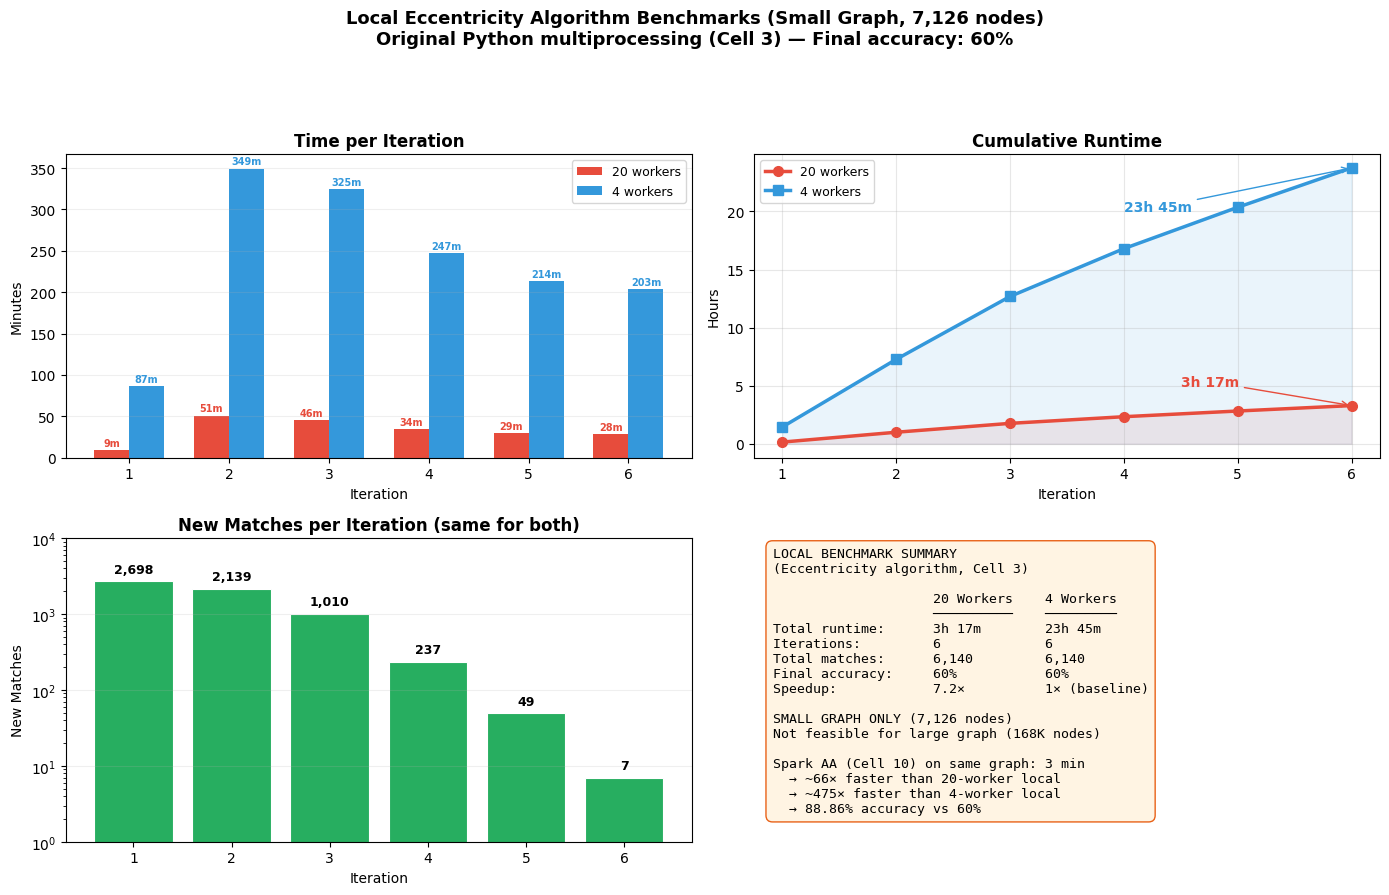

In [0]:
import matplotlib.pyplot as plt
import numpy as np

# ============================================
# Original local benchmarks (eccentricity algorithm, Cell 3)
# Small graph: 7,126 nodes | Final match: 60% accuracy
# Data exported from Excel
# ============================================

iters = [1, 2, 3, 4, 5, 6]

# Local #1: 20 workers
local1_iter_min  = [8.95, 50.9, 45.83, 34.38, 29.38, 28.03]   # minutes per iteration
local1_cumul_min = [8.95, 59.85, 105.68, 140.07, 169.45, 197.48]  # cumulative minutes
local1_matches   = [2698, 2139, 1010, 237, 49, 7]
local1_total     = [2698, 4837, 5847, 6084, 6133, 6140]

# Local #2: 4 workers
local2_iter_min  = [86.72, 349.37, 324.85, 247.0, 213.58, 203.33]  # minutes per iteration
local2_cumul_min = [86.72, 436.08, 760.93, 1007.93, 1221.52, 1424.85]  # cumulative minutes
local2_total     = [2698, 4837, 5847, 6084, 6133, 6140]

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
fig.suptitle('Local Eccentricity Algorithm Benchmarks (Small Graph, 7,126 nodes)\n'
             'Original Python multiprocessing (Cell 3) \u2014 Final accuracy: 60%',
             fontsize=13, fontweight='bold', y=0.99)

c20, c4 = '#e74c3c', '#3498db'

# ---- Panel 1: Time per iteration ----
ax = axes[0, 0]
x = np.arange(len(iters))
w = 0.35
ax.bar(x - w/2, local1_iter_min, w, label='20 workers', color=c20)
ax.bar(x + w/2, local2_iter_min, w, label='4 workers', color=c4)
ax.set_xlabel('Iteration')
ax.set_ylabel('Minutes')
ax.set_title('Time per Iteration', fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(iters)
ax.legend(fontsize=9)
ax.grid(True, alpha=0.2, axis='y')
for i, (t20, t4) in enumerate(zip(local1_iter_min, local2_iter_min)):
    ax.text(i - w/2, t20 + 5, f'{t20:.0f}m', ha='center', fontsize=7, fontweight='bold', color=c20)
    ax.text(i + w/2, t4 + 5, f'{t4:.0f}m', ha='center', fontsize=7, fontweight='bold', color=c4)

# ---- Panel 2: Cumulative runtime ----
ax = axes[0, 1]
ax.plot(iters, [t/60 for t in local1_cumul_min], 'o-', color=c20, linewidth=2.5, markersize=7, label='20 workers')
ax.plot(iters, [t/60 for t in local2_cumul_min], 's-', color=c4, linewidth=2.5, markersize=7, label='4 workers')
ax.fill_between(iters, [t/60 for t in local1_cumul_min], alpha=0.1, color=c20)
ax.fill_between(iters, [t/60 for t in local2_cumul_min], alpha=0.1, color=c4)
ax.set_xlabel('Iteration')
ax.set_ylabel('Hours')
ax.set_title('Cumulative Runtime', fontweight='bold')
ax.legend(fontsize=9)
ax.grid(True, alpha=0.3)
ax.annotate(f'3h 17m', xy=(6, local1_cumul_min[-1]/60), xytext=(4.5, 5),
            fontsize=10, fontweight='bold', color=c20,
            arrowprops=dict(arrowstyle='->', color=c20))
ax.annotate(f'23h 45m', xy=(6, local2_cumul_min[-1]/60), xytext=(4, 20),
            fontsize=10, fontweight='bold', color=c4,
            arrowprops=dict(arrowstyle='->', color=c4))

# ---- Panel 3: Matches per iteration ----
ax = axes[1, 0]
ax.bar(iters, local1_matches, color='#27ae60', edgecolor='white', linewidth=0.8)
ax.set_xlabel('Iteration')
ax.set_ylabel('New Matches')
ax.set_title('New Matches per Iteration (same for both)', fontweight='bold')
ax.set_yscale('log')
ax.set_ylim(1, 10000)
ax.grid(True, alpha=0.2, axis='y')
for i, nm in zip(iters, local1_matches):
    ax.text(i, nm * 1.3, f'{nm:,}', ha='center', fontsize=9, fontweight='bold')

# ---- Panel 4: Summary ----
ax = axes[1, 1]
ax.axis('off')
summary = """LOCAL BENCHMARK SUMMARY
(Eccentricity algorithm, Cell 3)

                    20 Workers    4 Workers
                    \u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500    \u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500
Total runtime:      3h 17m        23h 45m
Iterations:         6             6
Total matches:      6,140         6,140
Final accuracy:     60%           60%
Speedup:            7.2\u00d7          1\u00d7 (baseline)

SMALL GRAPH ONLY (7,126 nodes)
Not feasible for large graph (168K nodes)

Spark AA (Cell 10) on same graph: 3 min
  \u2192 ~66\u00d7 faster than 20-worker local
  \u2192 ~475\u00d7 faster than 4-worker local
  \u2192 88.86% accuracy vs 60%"""
ax.text(0.03, 0.97, summary, transform=ax.transAxes, fontsize=9.5,
        verticalalignment='top', fontfamily='monospace',
        bbox=dict(boxstyle='round,pad=0.5', facecolor='#fff3e0', edgecolor='#e65100', alpha=0.9))

plt.tight_layout(rect=[0, 0, 1, 0.93])
plt.show()

In [0]:
"""
Note:
Will only pass one iteration before failing due to memory constraints on a Serverless cluster. May potentially work for extremely small graphs, but not tested.
"""

import pyspark.sql.functions as F
from pyspark.sql.types import StructType, StructField, StringType, IntegerType, FloatType
import time

from datetime import datetime # for logging

# Helper function to normalize DBFS paths for serverless
def normalize_dbfs_path(path_str):
    path_str = path_str.strip()
    if path_str.startswith("dbfs:/Workspace/"):
        return "/" + path_str[6:]  # Remove "dbfs:/" prefix
    elif path_str.startswith("dbfs:") and not path_str.startswith("dbfs:/"):
        path_str = path_str.replace("dbfs:", "dbfs:/", 1)
    elif not path_str.startswith("dbfs:/") and not path_str.startswith("/"):
        path_str = f"/Workspace/Users/{path_str}"
    return path_str

# Serverless workarounds: read with Python and create DataFrames manually
def make_sparkdfs_from_edgelist(file_path): # to be used to mimic edgelists
    with open(file_path, 'r') as f:
        edges = [tuple(map(int, line.strip().split())) for line in f]

    # Edge DataFrame
    edge_df = spark.createDataFrame(edges, schema=StructType([
        StructField("src", IntegerType(), True),
        StructField("dest", IntegerType(), True)
    ]))

    # Node DataFrame
    nodes = set([src for src, dest in edges] + [dest for src, dest in edges])
    node_df = spark.createDataFrame([(n,) for n in nodes], schema=StructType([
        StructField("node", IntegerType(), True)
    ]))

    return node_df, edge_df

def make_sparkdfs_from_seeds(file_path): # to be used to mimic seed pairs
    with open(file_path, 'r') as f:
        pairs = [tuple(map(int, line.strip().split())) for line in f]

    return spark.createDataFrame(pairs, schema=StructType([
        StructField("l", IntegerType(), True),
        StructField("r", IntegerType(), True)
    ]))

def write_df_to_file(df, file_path):
    with open(file_path, 'a') as f:
        for row in df.collect():
            f.write(f"{row['l']}\t{row['r']}\n")
    return f"{df} written to {file_path} successfully."

# Logging function
def write_to_log(logfp, msg):
    timestamp = datetime.now().strftime("%Y-%m-%d %H:%M:%S")
    print(f"[{timestamp}] {msg}\n")
    with open(logfp, 'a') as f:
        f.write(f"[{timestamp}] {msg}\n")

# Numerator of Score formula: compute common, mapped/seeded neighbors between 2 nodes
def score_numerator(g1_node, g2_node, seeds_df):
    g1_neighbors = [row['dest'] for row in g1_edges.filter(F.col("src") == g1_node).select("dest").collect()]
    g2_neighbors = [row['dest'] for row in g2_edges.filter(F.col("src") == g2_node).select("dest").collect()]
    node_pairs = [(g1_neighbor, g2_neighbor) for g1_neighbor in g1_neighbors for g2_neighbor in g2_neighbors]
    seed_pairs = seeds_df.filter(F.col("l").isin([pair[0] for pair in node_pairs]) & F.col("r").isin([pair[1] for pair in node_pairs]))
    return seed_pairs.count()

# Denominator of Score = sqrt(degreeg1node*degreeg2node)
def score_denominator(g1_node, g2_node):
    g1_degree = g1_edges.filter(F.col("src") == g1_node).count()
    g2_degree = g2_edges.filter(F.col("src") == g2_node).count()
    return (g1_degree * g2_degree) ** 0.5


# Compute score for each pair of nodes in g1 and g2
def compute_similarity_scores(g1_nodes, g2_nodes, seeds_df):
    # Filter for g2_nodes that are NOT mapped in seeds_df, attempts to avoid multiple g1s matching to same g2
    g2_unmapped_nodes = g2_nodes.filter(~F.col("node").isin([row['r'] for row in seeds_df.select("r").distinct().collect()]))

    for g1_node_row in g1_nodes.collect():
        g1_node = g1_node_row['node']
        similarity = []
        max_score = 0
        max_score_node = None

        # Calculate similarity
        for g2_node_row in g2_unmapped_nodes.collect():
            g2_node = g2_node_row['node']
            numerator = score_numerator(g1_node, g2_node, seeds_df)
            denominator = score_denominator(g1_node, g2_node)
            if denominator == 0:
                continue
            score = numerator / denominator
            similarity.append(score)
            if score > max_score:
                max_score = score
                max_score_node = g2_node
        
        if max_score_node is None or len(similarity) < 2:
            continue
            
        # Calculate eccentricity as confidence score for match of g1 to max_score_node g2
        # ecc = (max-max2)/std
        # get max2 by removing max and getting max(similarity)
        similarity_copy = similarity.copy()
        similarity_copy.remove(max(similarity_copy))
        if not similarity_copy:
            continue
        max2 = max(similarity_copy)
        std = (sum(similarity) / len(similarity)) ** 0.5
        if std == 0:
            continue
        eccentricity = (max_score - max2) / std

        # Add new seed pair if eccen > confidence threshold of 0.5, where seed pair is (g1node, g2maxscorenode)
        if eccentricity > 0.5:
            seeds_df = seeds_df.union(spark.createDataFrame([(g1_node, max_score_node)], schema=StructType([
                StructField("l", IntegerType(), True),StructField("r", IntegerType(), True)
            ])))
            write_to_log(logfp, f"New seed pair found: {g1_node} -> {max_score_node}")

    return seeds_df

# Compare final guessed seeds to true seeds
def compare_output_to_true_seeds(outputdf, true_seeds_df, logfp):
    # Count how many output seeds appear in true_seeds_df
    true_l = [row['l'] for row in true_seeds_df.select("l").distinct().collect()]
    true_r = [row['r'] for row in true_seeds_df.select("r").distinct().collect()]
    correct_seeds_count = outputdf.filter(F.col("l").isin(true_l) & F.col("r").isin(true_r)).count()

    # Calc percentage of true seeds found
    match_percent = (correct_seeds_count / true_seeds_df.count()) * 100

    # Log results
    write_to_log(logfp, f"Number of correct seeds found: {correct_seeds_count}")
    write_to_log(logfp, f"As percentage: {match_percent}%")
    return


def deanonymize_spark(g1_nodes, g2_nodes, outputdf, trueseeds_df, logfp):
    # Start timer for iteration
    start_time = time.time()
    # Filter for nodes that are not mapped in outputdf
    output_l = [row['l'] for row in outputdf.select("l").distinct().collect()]
    output_r = [row['r'] for row in outputdf.select("r").distinct().collect()]
    g1_nodes_filtered = g1_nodes.filter(~F.col("node").isin(output_l))
    g2_nodes_filtered = g2_nodes.filter(~F.col("node").isin(output_r))

    # Compute new seeds
    seeds_df = compute_similarity_scores(g1_nodes_filtered, g2_nodes_filtered, outputdf)

    # Recurse until no new seeds
    if seeds_df.count() > outputdf.count():
        # Add new seeds to outputdf
        outputdf = seeds_df
        outputdf = outputdf.dropDuplicates(["l", "r"])

        # Log number of new seeds, elapsed time for iteration
        write_to_log(logfp, f"\n\n\n\n===========\nNew seeds found: {seeds_df.count() - outputdf.count()}")
        write_to_log(logfp, f"Elapsed time for iteration: {time.time() - start_time} seconds\n===========\n\n\n\n")
        deanonymize_spark(g1_nodes, g2_nodes, outputdf, trueseeds_df, logfp)
    else:
        # Report match %
        compare_output_to_true_seeds(outputdf, trueseeds_df, logfp)
        
        # Export outputdf to outputfp
        write_to_log(logfp, "No new seeds found. Exiting.")
        write_df_to_file(outputdf, outputfp)
        return

# Store filepaths from widgets as strings and normalize them
g1fp = normalize_dbfs_path(dbutils.widgets.get("g1fp"))
g2fp = normalize_dbfs_path(dbutils.widgets.get("g2fp"))
givenseedsfp = normalize_dbfs_path(dbutils.widgets.get("givenseedsfp"))
trueseedsfp = normalize_dbfs_path(dbutils.widgets.get("trueseedsfp"))
outputfp = normalize_dbfs_path(dbutils.widgets.get("outputfp"))
logfp = normalize_dbfs_path(dbutils.widgets.get("logfp"))

# Convert filepaths to DataFrames as separate node/edge lists or seeds as needed
g1_nodes, g1_edges = make_sparkdfs_from_edgelist(g1fp)
g2_nodes, g2_edges = make_sparkdfs_from_edgelist(g2fp)
givenseeds = make_sparkdfs_from_seeds(givenseedsfp)
trueseeds_df = make_sparkdfs_from_seeds(trueseedsfp)

# Instantiate outputfp as identical df to givenSeeds
outputdf = givenseeds

# Begin deanonymization
deanonymize_spark(g1_nodes, g2_nodes, outputdf, trueseeds_df, logfp)

com.databricks.backend.common.rpc.CommandCancelledException
	at com.databricks.spark.chauffeur.SequenceExecutionState.$anonfun$cancel$5(SequenceExecutionState.scala:139)
	at scala.Option.getOrElse(Option.scala:201)
	at com.databricks.spark.chauffeur.SequenceExecutionState.$anonfun$cancel$3(SequenceExecutionState.scala:139)
	at com.databricks.spark.chauffeur.SequenceExecutionState.$anonfun$cancel$3$adapted(SequenceExecutionState.scala:136)
	at scala.collection.immutable.Range.foreach(Range.scala:192)
	at com.databricks.spark.chauffeur.SequenceExecutionState.cancel(SequenceExecutionState.scala:136)
	at com.databricks.spark.chauffeur.ExecContextState.cancelRunningSequence(ExecContextState.scala:724)
	at com.databricks.spark.chauffeur.ExecContextState.$anonfun$cancel$1(ExecContextState.scala:442)
	at scala.Option.getOrElse(Option.scala:201)
	at com.databricks.spark.chauffeur.ExecContextState.cancel(ExecContextState.scala:442)
	at com.databricks.spark.chauffeur.ExecutionContextManagerV1.can

In [0]:
# ============================================
# HYBRID APPROACH: ITERATIVE FILTERING
# After each iteration, filter matched nodes from graphs
# ============================================

from pyspark.sql.functions import col, count, sqrt, desc, row_number, stddev, when, max as spark_max
from pyspark.sql.window import Window
from pyspark.sql.types import StructType, StructField, IntegerType
import time
from datetime import datetime

# ----------------------------
# PATH NORMALIZATION
# ----------------------------
def normalize_dbfs_path(path_str):
    path_str = path_str.strip()
    if path_str.startswith("dbfs:/Workspace/"):
        return "/" + path_str[6:]
    elif path_str.startswith("dbfs:") and not path_str.startswith("dbfs:/"):
        path_str = path_str.replace("dbfs:", "dbfs:/", 1)
    elif not path_str.startswith("dbfs:/") and not path_str.startswith("/"):
        path_str = f"/Workspace/Users/{path_str}"
    return path_str

# ----------------------------
# FILE READING
# ----------------------------
def load_edgelist_as_spark_df(file_path):
    with open(file_path, 'r') as f:
        edges = [tuple(map(int, line.strip().split())) for line in f]
    return spark.createDataFrame(edges, schema=StructType([
        StructField("u", IntegerType(), True),
        StructField("v", IntegerType(), True)
    ]))

def load_seeds_as_spark_df(file_path):
    with open(file_path, 'r') as f:
        pairs = [tuple(map(int, line.strip().split())) for line in f]
    return spark.createDataFrame(pairs, schema=StructType([
        StructField("l", IntegerType(), True),
        StructField("r", IntegerType(), True)
    ]))

# ----------------------------
# LOGGING
# ----------------------------
def write_to_log(logfp, msg):
    timestamp = datetime.now().strftime("%Y-%m-%d %H:%M:%S")
    log_line = f"[{timestamp}] {msg}"
    print(log_line)
    with open(logfp, 'a') as f:
        f.write(log_line + "\n")

# ----------------------------
# ITERATIVE ALGORITHM (NO MORE GRAPH FILTERING, found that it ruins prop. paths)
# ----------------------------
def deanonymize_iterative_filtering(g1_edges, g2_edges, seeds_df, logfp, 
                                     eccentricity_threshold=0.5, min_score=0.0, max_iterations=50):
    """
    Iteratively find matches using the full graph structure.
    Matched nodes are added to seeds but edges are preserved so
    newly matched nodes can serve as bridge connections.
    Already-matched left AND right nodes are excluded from scoring.
    """
    write_to_log(logfp, "Starting iterative deanonymization (full graph)...")
    write_to_log(logfp, f"Eccentricity threshold: {eccentricity_threshold}")
    
    # Make graphs undirected and cache (reused every iteration)
    g1_edges = g1_edges.union(g1_edges.select(col("v").alias("u"), col("u").alias("v")))
    g2_edges = g2_edges.union(g2_edges.select(col("v").alias("u"), col("u").alias("v")))
    g1_edges.cache()
    g2_edges.cache()
    
    # Compute degrees ONCE on the full (static) graphs
    g1_deg = g1_edges.groupBy("u").count().withColumnRenamed("count", "deg1").withColumnRenamed("u", "node1")
    g2_deg = g2_edges.groupBy("u").count().withColumnRenamed("count", "deg2").withColumnRenamed("u", "node2")
    g1_deg.cache()
    g2_deg.cache()
    
    # Initial node counts
    total_g1_nodes = g1_deg.count()
    total_g2_nodes = g2_deg.count()
    
    write_to_log(logfp, f"G1: {total_g1_nodes} nodes, G2: {total_g2_nodes} nodes")
    write_to_log(logfp, f"Initial seeds: {seeds_df.count()}")
    
    start_time = time.time()
    iteration = 0
    total_seeds = seeds_df.count()
    
    while iteration < max_iterations:
        iteration += 1
        iter_start = time.time()
        write_to_log(logfp, f"\n=== Iteration {iteration} ===")
        
        unmatched_g1 = total_g1_nodes - total_seeds
        write_to_log(logfp, f"Unmatched G1 nodes: {unmatched_g1}")
        
        if unmatched_g1 <= 0:
            write_to_log(logfp, "All G1 nodes matched!")
            break
        
        # Find G1 neighbors that are in seeds (mapped neighbors)
        # Use aliases to avoid ambiguous column references after union/checkpoint
        g1_a = g1_edges.alias("g1")
        s1 = seeds_df.alias("s1")
        g1_mapped_neighbors = g1_a.join(s1, col("g1.v") == col("s1.l")) \
            .select(col("g1.u").alias("leftNode"), col("s1.r").alias("mappedRightNeighbor"))
        
        # Find G2 neighbors that are in seeds
        g2_a = g2_edges.alias("g2")
        s2 = seeds_df.alias("s2")
        g2_neighbors_in_seeds = g2_a.join(s2, col("g2.v") == col("s2.r")) \
            .select(col("g2.u").alias("rightNode"), col("g2.v").alias("rightNeighbor"))
        
        # Find shared mapped neighbors
        matches = g1_mapped_neighbors.join(
            g2_neighbors_in_seeds,
            g1_mapped_neighbors.mappedRightNeighbor == g2_neighbors_in_seeds.rightNeighbor
        )
        
        matches_count = matches.count()
        write_to_log(logfp, f"Potential matches: {matches_count}")
        
        if matches_count == 0:
            write_to_log(logfp, "No shared mapped neighbors found.")
            break
        
        # Count shared neighbors per (leftNode, rightNode) pair
        scores = matches.groupBy("leftNode", "rightNode") \
            .agg(count("*").alias("sharedMappedNeighbors"))
        
        # Exclude leftNodes already in seeds_df (already matched)
        seeds_left = seeds_df.select(col("l").alias("leftNode")).distinct()
        scores = scores.join(seeds_left, "leftNode", "left_anti")
        
        # Exclude rightNodes already in seeds_df (prevent many-to-one mappings)
        seeds_right = seeds_df.select(col("r").alias("rightNode")).distinct()
        scores = scores.join(seeds_right, "rightNode", "left_anti")
        
        remaining_candidates = scores.select("leftNode").distinct().count()
        write_to_log(logfp, f"Unmatched candidates with shared neighbors: {remaining_candidates}")
        
        if remaining_candidates == 0:
            write_to_log(logfp, "No unmatched candidates remain.")
            break
        
        # Join with degrees and calculate similarity score
        scores = scores \
            .join(g1_deg, scores.leftNode == g1_deg.node1) \
            .join(g2_deg, scores.rightNode == g2_deg.node2) \
            .withColumn(
                "score", 
                col("sharedMappedNeighbors") / (sqrt(col("deg1")) * sqrt(col("deg2")))
            )
        
        # Rank candidates for each leftNode
        window = Window.partitionBy("leftNode").orderBy(desc("score"))
        scores = scores.withColumn("rank", row_number().over(window))
        
        # Calculate eccentricity: (max - second_max) / stddev
        node_stats = scores.groupBy("leftNode").agg(
            spark_max(when(col("rank") == 1, col("score"))).alias("max_score"),
            spark_max(when(col("rank") == 1, col("rightNode"))).alias("topRightNode"),
            spark_max(when(col("rank") == 2, col("score"))).alias("second_max_score"),
            stddev("score").alias("score_stddev")
        )
        
        candidates = node_stats.withColumn(
            "eccentricity",
            when(
                (col("second_max_score").isNotNull()) & 
                (col("score_stddev").isNotNull()) & 
                (col("score_stddev") > 0),
                (col("max_score") - col("second_max_score")) / col("score_stddev")
            ).otherwise(None)
        )
        
        # Filter candidates meeting thresholds
        new_matches = candidates.filter(
            (col("eccentricity").isNotNull()) &
            (col("eccentricity") > eccentricity_threshold) &
            (col("max_score") >= min_score)
        ).select(col("leftNode").alias("l"), col("topRightNode").alias("r"))
        
        new_count = new_matches.count()
        write_to_log(logfp, f"New matches found: {new_count}")
        
        if new_count > 0:
            # Log top eccentricity values
            top_ecc = candidates.filter(col("eccentricity").isNotNull()) \
                .orderBy(desc("eccentricity")).limit(3).collect()
            write_to_log(logfp, f"Top eccentricities: {[(r.leftNode, r.topRightNode, round(r.eccentricity, 3)) for r in top_ecc]}")
            
            # Log sample matches
            sample = new_matches.limit(5).collect()
            write_to_log(logfp, f"Sample matches: {[(r.l, r.r) for r in sample]}")
            
            # Add new matches to seeds and break lineage
            seeds_df = seeds_df.union(new_matches).distinct()
            seeds_df = seeds_df.localCheckpoint(eager=True)
            total_seeds = seeds_df.count()
        else:
            write_to_log(logfp, "No matches met threshold criteria.")
            break
        
        iter_time = time.time() - iter_start
        total_time = time.time() - start_time
        progress = (total_seeds / total_g1_nodes) * 100
        
        write_to_log(logfp, f"Total seeds: {total_seeds}")
        write_to_log(logfp, f"Progress: {progress:.2f}%")
        write_to_log(logfp, f"Iteration time: {iter_time:.2f}s, Total: {total_time:.2f}s")
    
    if iteration >= max_iterations:
        write_to_log(logfp, f"Reached max iterations ({max_iterations})")
    
    # Unpersist cached DataFrames
    g1_edges.unpersist()
    g2_edges.unpersist()
    g1_deg.unpersist()
    g2_deg.unpersist()
    
    return seeds_df

# ----------------------------
# COMPARISON FUNCTION
# ----------------------------
def compare_seeds(calculated_df, true_df, logfp):
    shared = calculated_df.join(true_df, ["l", "r"])
    match_count = shared.count()
    total_true = true_df.count()
    total_calc = calculated_df.count()
    match_percent = round((match_count / total_true) * 100, 3)
    
    write_to_log(logfp, "\n=== FINAL RESULTS ===")
    write_to_log(logfp, f"Calculated seeds: {total_calc}")
    write_to_log(logfp, f"True seeds: {total_true}")
    write_to_log(logfp, f"Correct matches: {match_count}")
    write_to_log(logfp, f"Accuracy: {match_percent}%")

# ----------------------------
# OUTPUT FUNCTION
# ----------------------------
def write_seeds_to_file(seeds_df, output_path):
    with open(output_path, 'w') as f:
        for row in seeds_df.collect():
            f.write(f"{row['l']} {row['r']}\n")

# ----------------------------
# MAIN EXECUTION
# ----------------------------

g1fp = normalize_dbfs_path(dbutils.widgets.get("g1fp"))
g2fp = normalize_dbfs_path(dbutils.widgets.get("g2fp"))
givenseedsfp = normalize_dbfs_path(dbutils.widgets.get("givenseedsfp"))
trueseedsfp = normalize_dbfs_path(dbutils.widgets.get("trueseedsfp"))
outputfp = normalize_dbfs_path(dbutils.widgets.get("outputfp"))
logfp = normalize_dbfs_path(dbutils.widgets.get("logfp"))

write_to_log(logfp, "="*50)
write_to_log(logfp, "ITERATIVE DEANONYMIZATION (FULL GRAPH, ECCEN=1.0)")
write_to_log(logfp, "="*50)

total_start = time.time()
write_to_log(logfp, "Loading graphs...")
g1_edges = load_edgelist_as_spark_df(g1fp)
g2_edges = load_edgelist_as_spark_df(g2fp)
initial_seeds = load_seeds_as_spark_df(givenseedsfp)
true_seeds = load_seeds_as_spark_df(trueseedsfp)
write_to_log(logfp, "Graphs loaded.")

# Run algorithm with HIGHER eccentricity threshold (1.0 vs previous 0.5) as test
final_seeds = deanonymize_iterative_filtering(
    g1_edges, g2_edges, initial_seeds, logfp,
    eccentricity_threshold=1.0,
    min_score=0.0,
    max_iterations=50
)

# Compare results
compare_seeds(final_seeds, true_seeds, logfp)

# Write output
write_to_log(logfp, f"\nWriting to {outputfp}...")
write_seeds_to_file(final_seeds, outputfp)

total_time = time.time() - total_start
write_to_log(logfp, f"Total time: {total_time:.2f}s")
write_to_log(logfp, "="*50)

print("\n\u2713 Complete! Check log for details.")

[2026-04-11 02:36:44] ==================================================
[2026-04-11 02:36:44] ITERATIVE DEANONYMIZATION (FULL GRAPH, ECCEN=1.0)
[2026-04-11 02:36:44] ==================================================
[2026-04-11 02:36:44] Loading graphs...
[2026-04-11 02:36:45] Graphs loaded.
[2026-04-11 02:36:45] Starting iterative deanonymization (full graph)...
[2026-04-11 02:36:45] Eccentricity threshold: 1.0
[2026-04-11 02:36:59] G1: 7126 nodes, G2: 7126 nodes
[2026-04-11 02:36:59] Initial seeds: 500
[2026-04-11 02:36:59] 
=== Iteration 1 ===
[2026-04-11 02:36:59] Unmatched G1 nodes: 6626
[2026-04-11 02:37:01] Potential matches: 2900540
[2026-04-11 02:37:04] Unmatched candidates with shared neighbors: 4454
[2026-04-11 02:37:16] New matches found: 1421
[2026-04-11 02:37:26] Top eccentricities: [(4439, 6910, 10.405), (3819, 2006, 8.355), (1924, 671, 8.345)]
[2026-04-11 02:37:38] Sample matches: [(44, 1117), (47, 3951), (65, 6771), (76, 3037), (85, 4465)]
[2026-04-11 02:37:49] Total

com.databricks.backend.common.rpc.CommandCancelledException
	at com.databricks.spark.chauffeur.SequenceExecutionState.$anonfun$cancel$5(SequenceExecutionState.scala:139)
	at scala.Option.getOrElse(Option.scala:201)
	at com.databricks.spark.chauffeur.SequenceExecutionState.$anonfun$cancel$3(SequenceExecutionState.scala:139)
	at com.databricks.spark.chauffeur.SequenceExecutionState.$anonfun$cancel$3$adapted(SequenceExecutionState.scala:136)
	at scala.collection.immutable.Range.foreach(Range.scala:192)
	at com.databricks.spark.chauffeur.SequenceExecutionState.cancel(SequenceExecutionState.scala:136)
	at com.databricks.spark.chauffeur.ExecContextState.cancelRunningSequence(ExecContextState.scala:724)
	at com.databricks.spark.chauffeur.ExecContextState.$anonfun$cancel$1(ExecContextState.scala:442)
	at scala.Option.getOrElse(Option.scala:201)
	at com.databricks.spark.chauffeur.ExecContextState.cancel(ExecContextState.scala:442)
	at com.databricks.spark.chauffeur.ExecutionContextManagerV1.can

In [0]:
# ============================================
# SHARED HELPER FUNCTIONS
# Run this cell first to define utilities used by all algorithm cells
# ============================================

# Clear all cached DataFrames for a fresh start
spark.catalog.clearCache()
print("\u2713 All Spark caches cleared.")

from pyspark.sql.functions import col
from pyspark.sql.types import StructType, StructField, IntegerType
from datetime import datetime

def normalize_dbfs_path(path_str):
    path_str = path_str.strip()
    if path_str.startswith("dbfs:/Workspace/"):
        return "/" + path_str[6:]
    elif path_str.startswith("dbfs:") and not path_str.startswith("dbfs:/"):
        path_str = path_str.replace("dbfs:", "dbfs:/", 1)
    elif not path_str.startswith("dbfs:/") and not path_str.startswith("/"):
        path_str = f"/Workspace/Users/{path_str}"
    return path_str

def load_edgelist_as_spark_df(file_path):
    with open(file_path, 'r') as f:
        edges = [tuple(map(int, line.strip().split())) for line in f]
    return spark.createDataFrame(edges, schema=StructType([
        StructField("u", IntegerType(), True),
        StructField("v", IntegerType(), True)
    ]))

def load_seeds_as_spark_df(file_path):
    with open(file_path, 'r') as f:
        pairs = [tuple(map(int, line.strip().split())) for line in f]
    return spark.createDataFrame(pairs, schema=StructType([
        StructField("l", IntegerType(), True),
        StructField("r", IntegerType(), True)
    ]))

def write_to_log(logfp, msg):
    timestamp = datetime.now().strftime("%Y-%m-%d %H:%M:%S")
    log_line = f"[{timestamp}] {msg}"
    print(log_line)
    with open(logfp, 'a') as f:
        f.write(log_line + "\n")

def compare_seeds(calculated_df, true_df, logfp):
    shared = calculated_df.join(true_df, ["l", "r"])
    match_count = shared.count()
    total_true = true_df.count()
    total_calc = calculated_df.count()
    match_percent = round((match_count / total_true) * 100, 3)
    write_to_log(logfp, "\n=== FINAL RESULTS ===")
    write_to_log(logfp, f"Calculated seeds: {total_calc}")
    write_to_log(logfp, f"True seeds: {total_true}")
    write_to_log(logfp, f"Correct matches: {match_count}")
    write_to_log(logfp, f"Accuracy: {match_percent}%")

def write_seeds_to_file(seeds_df, output_path):
    with open(output_path, 'w') as f:
        for row in seeds_df.collect():
            f.write(f"{row['l']} {row['r']}\n")

print("\u2713 All helper functions defined.")

✓ All Spark caches cleared.
✓ All helper functions defined.


In [0]:
# ============================================
# JACCARD SIMILARITY APPROACH
# Uses J(u,v) = |shared mapped neighbors| / |union of mapped neighbors|
# instead of eccentricity-based confidence scoring
# ============================================

from pyspark.sql.functions import col, count, sqrt, desc, row_number, broadcast
from pyspark.sql.window import Window
from pyspark.sql.types import StructType, StructField, IntegerType
import time
from datetime import datetime

def deanonymize_jaccard(g1_edges, g2_edges, seeds_df, logfp,
                        jaccard_threshold=0.3, max_iterations=50):
    """
    Iteratively match nodes using Jaccard similarity over mapped neighbors.
    J(u,v) = |mapped_nbrs(u) ∩ mapped_nbrs(v)| / |mapped_nbrs(u) ∪ mapped_nbrs(v)|
    Enforces one-to-one matching via mutual best-match selection.
    """
    write_to_log(logfp, "Starting Jaccard-based deanonymization...")
    write_to_log(logfp, f"Jaccard threshold: {jaccard_threshold}")

    # Make graphs undirected and cache
    g1_edges = g1_edges.union(g1_edges.select(col("v").alias("u"), col("u").alias("v")))
    g2_edges = g2_edges.union(g2_edges.select(col("v").alias("u"), col("u").alias("v")))
    g1_edges.cache()
    g2_edges.cache()

    total_g1_nodes = g1_edges.select("u").distinct().count()
    total_g2_nodes = g2_edges.select("u").distinct().count()

    write_to_log(logfp, f"G1: {total_g1_nodes} nodes, G2: {total_g2_nodes} nodes")
    write_to_log(logfp, f"Initial seeds: {seeds_df.count()}")

    start_time = time.time()
    iteration = 0
    total_seeds = seeds_df.count()

    while iteration < max_iterations:
        iteration += 1
        iter_start = time.time()
        write_to_log(logfp, f"\n=== Iteration {iteration} ===")

        unmatched_g1 = total_g1_nodes - total_seeds
        write_to_log(logfp, f"Unmatched G1 nodes: {unmatched_g1}")

        if unmatched_g1 <= 0:
            write_to_log(logfp, "All G1 nodes matched!")
            break

        # --- Mapped neighbors ---
        g1_a = g1_edges.alias("g1")
        s1 = seeds_df.alias("s1")
        g1_mapped_neighbors = g1_a.join(s1, col("g1.v") == col("s1.l")) \
            .select(col("g1.u").alias("leftNode"), col("s1.r").alias("mappedRightNeighbor"))

        g2_a = g2_edges.alias("g2")
        s2 = seeds_df.alias("s2")
        g2_mapped_neighbors = g2_a.join(s2, col("g2.v") == col("s2.r")) \
            .select(col("g2.u").alias("rightNode"), col("g2.v").alias("mappedRightNeighbor"))

        # --- Count mapped neighbors per node (for Jaccard denominator) ---
        g1_mapped_count = g1_mapped_neighbors.groupBy("leftNode") \
            .agg(count("*").alias("g1_mapped_cnt"))
        g2_mapped_count = g2_mapped_neighbors.groupBy("rightNode") \
            .agg(count("*").alias("g2_mapped_cnt"))

        # --- Shared mapped neighbors (intersection) ---
        shared = g1_mapped_neighbors.join(
            g2_mapped_neighbors,
            "mappedRightNeighbor"
        )

        scores = shared.groupBy("leftNode", "rightNode") \
            .agg(count("*").alias("shared_cnt"))

        # Exclude already-matched left and right nodes
        seeds_left = seeds_df.select(col("l").alias("leftNode")).distinct()
        seeds_right = seeds_df.select(col("r").alias("rightNode")).distinct()
        scores = scores.join(seeds_left, "leftNode", "left_anti")
        scores = scores.join(seeds_right, "rightNode", "left_anti")

        remaining = scores.select("leftNode").distinct().count()
        write_to_log(logfp, f"Unmatched candidates with shared neighbors: {remaining}")

        if remaining == 0:
            write_to_log(logfp, "No unmatched candidates remain.")
            break

        # --- Jaccard = shared / (g1_cnt + g2_cnt - shared) ---
        scores = scores \
            .join(g1_mapped_count, "leftNode") \
            .join(g2_mapped_count, "rightNode") \
            .withColumn(
                "jaccard",
                col("shared_cnt") / (col("g1_mapped_cnt") + col("g2_mapped_cnt") - col("shared_cnt"))
            )

        # --- One-to-one matching: mutual best match ---
        # Best rightNode per leftNode
        w_left = Window.partitionBy("leftNode").orderBy(desc("jaccard"))
        best_per_left = scores.withColumn("rk_l", row_number().over(w_left)) \
            .filter(col("rk_l") == 1)

        # Among those, best leftNode per rightNode (resolve collisions)
        w_right = Window.partitionBy("rightNode").orderBy(desc("jaccard"))
        best_matches = best_per_left.withColumn("rk_r", row_number().over(w_right)) \
            .filter(col("rk_r") == 1)

        # Apply Jaccard threshold
        new_matches = best_matches.filter(col("jaccard") >= jaccard_threshold) \
            .select(col("leftNode").alias("l"), col("rightNode").alias("r"))

        new_count = new_matches.count()
        write_to_log(logfp, f"New matches found: {new_count}")

        if new_count > 0:
            top = best_matches.filter(col("jaccard") >= jaccard_threshold) \
                .orderBy(desc("jaccard")).limit(3).collect()
            write_to_log(logfp, f"Top Jaccard scores: {[(r.leftNode, r.rightNode, round(r.jaccard, 4)) for r in top]}")

            sample = new_matches.limit(5).collect()
            write_to_log(logfp, f"Sample matches: {[(r.l, r.r) for r in sample]}")

            seeds_df = seeds_df.union(new_matches).distinct()
            seeds_df = seeds_df.localCheckpoint(eager=True)
            total_seeds = seeds_df.count()
        else:
            write_to_log(logfp, "No matches met Jaccard threshold.")
            break

        iter_time = time.time() - iter_start
        total_time = time.time() - start_time
        progress = (total_seeds / total_g1_nodes) * 100

        write_to_log(logfp, f"Total seeds: {total_seeds}")
        write_to_log(logfp, f"Progress: {progress:.2f}%")
        write_to_log(logfp, f"Iteration time: {iter_time:.2f}s, Total: {total_time:.2f}s")

    if iteration >= max_iterations:
        write_to_log(logfp, f"Reached max iterations ({max_iterations})")

    g1_edges.unpersist()
    g2_edges.unpersist()
    return seeds_df

# ----------------------------
# MAIN EXECUTION
# ----------------------------
g1fp = normalize_dbfs_path(dbutils.widgets.get("g1fp"))
g2fp = normalize_dbfs_path(dbutils.widgets.get("g2fp"))
givenseedsfp = normalize_dbfs_path(dbutils.widgets.get("givenseedsfp"))
trueseedsfp = normalize_dbfs_path(dbutils.widgets.get("trueseedsfp"))
outputfp = normalize_dbfs_path(dbutils.widgets.get("outputfp"))
logfp = normalize_dbfs_path(dbutils.widgets.get("logfp"))

write_to_log(logfp, "="*50)
write_to_log(logfp, "JACCARD SIMILARITY DEANONYMIZATION")
write_to_log(logfp, "="*50)

total_start = time.time()
write_to_log(logfp, "Loading graphs...")
g1_edges = load_edgelist_as_spark_df(g1fp)
g2_edges = load_edgelist_as_spark_df(g2fp)
initial_seeds = load_seeds_as_spark_df(givenseedsfp)
true_seeds = load_seeds_as_spark_df(trueseedsfp)
write_to_log(logfp, "Graphs loaded.")

final_seeds = deanonymize_jaccard(
    g1_edges, g2_edges, initial_seeds, logfp,
    jaccard_threshold=0.3,
    max_iterations=50
)

compare_seeds(final_seeds, true_seeds, logfp)

write_to_log(logfp, f"\nWriting to {outputfp}...")
write_seeds_to_file(final_seeds, outputfp)

total_time = time.time() - total_start
write_to_log(logfp, f"Total time: {total_time:.2f}s")
write_to_log(logfp, "="*50)

print("\n✓ Jaccard approach complete! Check log for details.")

com.databricks.backend.common.rpc.CommandSkippedException
	at com.databricks.spark.chauffeur.SequenceExecutionState.$anonfun$cancel$3(SequenceExecutionState.scala:141)
	at com.databricks.spark.chauffeur.SequenceExecutionState.$anonfun$cancel$3$adapted(SequenceExecutionState.scala:136)
	at scala.collection.immutable.Range.foreach(Range.scala:192)
	at com.databricks.spark.chauffeur.SequenceExecutionState.cancel(SequenceExecutionState.scala:136)
	at com.databricks.spark.chauffeur.ExecContextState.cancelRunningSequence(ExecContextState.scala:724)
	at com.databricks.spark.chauffeur.ExecContextState.$anonfun$cancel$1(ExecContextState.scala:442)
	at scala.Option.getOrElse(Option.scala:201)
	at com.databricks.spark.chauffeur.ExecContextState.cancel(ExecContextState.scala:442)
	at com.databricks.spark.chauffeur.ExecutionContextManagerV1.cancelExecution(ExecutionContextManagerV1.scala:495)
	at com.databricks.spark.chauffeur.ChauffeurState.$anonfun$process$1(ChauffeurState.scala:725)
	at com.data

In [0]:
# ============================================
# ADAMIC-ADAR SIMILARITY APPROACH
# Weights each shared mapped neighbor by 1/log(degree)
# Low-degree (specific) neighbors contribute more than hubs
# ============================================

from pyspark.sql.functions import col, count, sum as spark_sum, log as spark_log, desc, row_number, lit
from pyspark.sql.window import Window
from pyspark.sql.types import StructType, StructField, IntegerType
import time
from datetime import datetime

def deanonymize_adamic_adar(g1_edges, g2_edges, seeds_df, logfp,
                            score_threshold=0.5, max_iterations=50):
    """
    Iteratively match nodes using Adamic-Adar similarity.
    AA(u,v) = sum over shared mapped neighbors w of: 1 / log(deg(w))
    Low-degree shared neighbors are weighted higher (more "specific" links).
    Enforces one-to-one matching via mutual best-match selection.
    """
    write_to_log(logfp, "Starting Adamic-Adar deanonymization...")
    write_to_log(logfp, f"Score threshold: {score_threshold}")

    # Make graphs undirected and cache
    g1_edges = g1_edges.union(g1_edges.select(col("v").alias("u"), col("u").alias("v")))
    g2_edges = g2_edges.union(g2_edges.select(col("v").alias("u"), col("u").alias("v")))
    g1_edges.cache()
    g2_edges.cache()

    # Compute degrees ONCE (used to weight shared neighbors)
    g2_deg = g2_edges.groupBy("u").count() \
        .withColumnRenamed("count", "nbr_deg") \
        .withColumnRenamed("u", "nbr_node")
    g2_deg.cache()

    total_g1_nodes = g1_edges.select("u").distinct().count()
    total_g2_nodes = g2_edges.select("u").distinct().count()

    write_to_log(logfp, f"G1: {total_g1_nodes} nodes, G2: {total_g2_nodes} nodes")
    write_to_log(logfp, f"Initial seeds: {seeds_df.count()}")

    start_time = time.time()
    iteration = 0
    total_seeds = seeds_df.count()

    while iteration < max_iterations:
        iteration += 1
        iter_start = time.time()
        write_to_log(logfp, f"\n=== Iteration {iteration} ===")

        unmatched_g1 = total_g1_nodes - total_seeds
        write_to_log(logfp, f"Unmatched G1 nodes: {unmatched_g1}")

        if unmatched_g1 <= 0:
            write_to_log(logfp, "All G1 nodes matched!")
            break

        # --- Mapped neighbors ---
        g1_a = g1_edges.alias("g1")
        s1 = seeds_df.alias("s1")
        g1_mapped_neighbors = g1_a.join(s1, col("g1.v") == col("s1.l")) \
            .select(col("g1.u").alias("leftNode"), col("s1.r").alias("mappedRightNeighbor"))

        g2_a = g2_edges.alias("g2")
        s2 = seeds_df.alias("s2")
        g2_mapped_neighbors = g2_a.join(s2, col("g2.v") == col("s2.r")) \
            .select(col("g2.u").alias("rightNode"), col("g2.v").alias("mappedRightNeighbor"))

        # --- Shared mapped neighbors with degree-based weighting ---
        shared = g1_mapped_neighbors.join(
            g2_mapped_neighbors,
            "mappedRightNeighbor"
        )

        # Join with G2 degree of shared neighbor for Adamic-Adar weight
        # Weight = 1 / log(degree); skip degree <= 1 to avoid log(1)=0 division
        shared_weighted = shared.join(
            g2_deg,
            shared.mappedRightNeighbor == g2_deg.nbr_node
        ).filter(col("nbr_deg") > 1) \
         .withColumn("aa_weight", lit(1.0) / spark_log(col("nbr_deg")))

        # Sum AA weights per (leftNode, rightNode) pair
        scores = shared_weighted.groupBy("leftNode", "rightNode") \
            .agg(
                spark_sum("aa_weight").alias("aa_score"),
                count("*").alias("shared_cnt")
            )

        # Exclude already-matched left and right nodes
        seeds_left = seeds_df.select(col("l").alias("leftNode")).distinct()
        seeds_right = seeds_df.select(col("r").alias("rightNode")).distinct()
        scores = scores.join(seeds_left, "leftNode", "left_anti")
        scores = scores.join(seeds_right, "rightNode", "left_anti")

        remaining = scores.select("leftNode").distinct().count()
        write_to_log(logfp, f"Unmatched candidates with shared neighbors: {remaining}")

        if remaining == 0:
            write_to_log(logfp, "No unmatched candidates remain.")
            break

        # --- One-to-one matching: mutual best match ---
        w_left = Window.partitionBy("leftNode").orderBy(desc("aa_score"))
        best_per_left = scores.withColumn("rk_l", row_number().over(w_left)) \
            .filter(col("rk_l") == 1)

        w_right = Window.partitionBy("rightNode").orderBy(desc("aa_score"))
        best_matches = best_per_left.withColumn("rk_r", row_number().over(w_right)) \
            .filter(col("rk_r") == 1)

        # Apply score threshold
        new_matches = best_matches.filter(col("aa_score") >= score_threshold) \
            .select(col("leftNode").alias("l"), col("rightNode").alias("r"))

        new_count = new_matches.count()
        write_to_log(logfp, f"New matches found: {new_count}")

        if new_count > 0:
            top = best_matches.filter(col("aa_score") >= score_threshold) \
                .orderBy(desc("aa_score")).limit(3).collect()
            write_to_log(logfp, f"Top AA scores: {[(r.leftNode, r.rightNode, round(r.aa_score, 4), r.shared_cnt) for r in top]}")

            sample = new_matches.limit(5).collect()
            write_to_log(logfp, f"Sample matches: {[(r.l, r.r) for r in sample]}")

            # localCheckpoint is safe on single-node clusters (no executor loss)
            seeds_df = seeds_df.union(new_matches).distinct()
            seeds_df = seeds_df.localCheckpoint(eager=True)
            total_seeds = seeds_df.count()
        else:
            write_to_log(logfp, "No matches met AA score threshold.")
            break

        iter_time = time.time() - iter_start
        total_time = time.time() - start_time
        progress = (total_seeds / total_g1_nodes) * 100

        write_to_log(logfp, f"Total seeds: {total_seeds}")
        write_to_log(logfp, f"Progress: {progress:.2f}%")
        write_to_log(logfp, f"Iteration time: {iter_time:.2f}s, Total: {total_time:.2f}s")

    if iteration >= max_iterations:
        write_to_log(logfp, f"Reached max iterations ({max_iterations})")

    g1_edges.unpersist()
    g2_edges.unpersist()
    g2_deg.unpersist()
    return seeds_df

# ----------------------------
# MAIN EXECUTION
# ----------------------------
g1fp = normalize_dbfs_path(dbutils.widgets.get("g1fp"))
g2fp = normalize_dbfs_path(dbutils.widgets.get("g2fp"))
givenseedsfp = normalize_dbfs_path(dbutils.widgets.get("givenseedsfp"))
trueseedsfp = normalize_dbfs_path(dbutils.widgets.get("trueseedsfp"))
outputfp = normalize_dbfs_path(dbutils.widgets.get("outputfp"))
logfp = normalize_dbfs_path(dbutils.widgets.get("logfp"))

write_to_log(logfp, "="*50)
write_to_log(logfp, "ADAMIC-ADAR DEANONYMIZATION")
write_to_log(logfp, "="*50)

total_start = time.time()
write_to_log(logfp, "Loading graphs...")
g1_edges = load_edgelist_as_spark_df(g1fp)
g2_edges = load_edgelist_as_spark_df(g2fp)
initial_seeds = load_seeds_as_spark_df(givenseedsfp)
true_seeds = load_seeds_as_spark_df(trueseedsfp)
write_to_log(logfp, "Graphs loaded.")

final_seeds = deanonymize_adamic_adar(
    g1_edges, g2_edges, initial_seeds, logfp,
    score_threshold=0.5,
    max_iterations=50
)

compare_seeds(final_seeds, true_seeds, logfp)

write_to_log(logfp, f"\nWriting to {outputfp}...")
write_seeds_to_file(final_seeds, outputfp)

total_time = time.time() - total_start
write_to_log(logfp, f"Total time: {total_time:.2f}s")
write_to_log(logfp, "="*50)

print("\n\u2713 Adamic-Adar approach complete! Check log for details.")

[2026-04-11 23:42:26] ==================================================
[2026-04-11 23:42:26] ADAMIC-ADAR DEANONYMIZATION
[2026-04-11 23:42:26] ==================================================
[2026-04-11 23:42:26] Loading graphs...
[2026-04-11 23:42:27] Graphs loaded.
[2026-04-11 23:42:27] Starting Adamic-Adar deanonymization...
[2026-04-11 23:42:27] Score threshold: 0.5
[2026-04-11 23:42:31] G1: 7126 nodes, G2: 7126 nodes
[2026-04-11 23:42:31] Initial seeds: 500
[2026-04-11 23:42:32] 
=== Iteration 1 ===
[2026-04-11 23:42:32] Unmatched G1 nodes: 6626
[2026-04-11 23:42:48] Unmatched candidates with shared neighbors: 4454
[2026-04-11 23:43:04] New matches found: 1717
[2026-04-11 23:43:19] Top AA scores: [(1924, 671, 22.314, 71), (2732, 12, 8.322, 24), (4328, 2191, 8.3138, 31)]
[2026-04-11 23:43:29] Sample matches: [(4012, 5), (3763, 9), (3692, 10), (2732, 12), (5743, 17)]
[2026-04-11 23:43:45] Total seeds: 2217
[2026-04-11 23:43:45] Progress: 31.11%
[2026-04-11 23:43:45] Iteration t

In [0]:
# ============================================
# ADAMIC-ADAR SIMILARITY APPROACH (MULTI-NODE)
# Weights each shared mapped neighbor by 1/log(degree)
# Low-degree (specific) neighbors contribute more than hubs
# Breaks lineage via parquet write/read on UC Volume (shared-cluster safe)
# ============================================

from pyspark.sql.functions import col, count, sum as spark_sum, log as spark_log, desc, row_number, lit
from pyspark.sql.window import Window
from pyspark.sql.types import StructType, StructField, IntegerType
import time
from datetime import datetime

# Temp path on UC Volume for lineage-breaking writes
SEEDS_TEMP_PATH = "/Volumes/custom_compute/default/deanon_project/temp_seeds"

def deanonymize_adamic_adar(g1_edges, g2_edges, seeds_df, logfp,
                            score_threshold=1.5, max_iterations=50):
    """
    Iteratively match nodes using Adamic-Adar similarity.
    AA(u,v) = sum over shared mapped neighbors w of: 1 / log(deg(w))
    Low-degree shared neighbors are weighted higher (more "specific" links).
    Enforces one-to-one matching via mutual best-match selection.
    Breaks lineage by writing seeds to UC Volume (shared-cluster compatible).
    """
    write_to_log(logfp, "Starting Adamic-Adar deanonymization...")
    write_to_log(logfp, f"Score threshold: {score_threshold}")

    # Make graphs undirected and cache
    g1_edges = g1_edges.union(g1_edges.select(col("v").alias("u"), col("u").alias("v")))
    g2_edges = g2_edges.union(g2_edges.select(col("v").alias("u"), col("u").alias("v")))
    g1_edges.cache()
    g2_edges.cache()

    # Compute degrees ONCE (used to weight shared neighbors)
    g2_deg = g2_edges.groupBy("u").count() \
        .withColumnRenamed("count", "nbr_deg") \
        .withColumnRenamed("u", "nbr_node")
    g2_deg.cache()

    total_g1_nodes = g1_edges.select("u").distinct().count()
    total_g2_nodes = g2_edges.select("u").distinct().count()

    write_to_log(logfp, f"G1: {total_g1_nodes} nodes, G2: {total_g2_nodes} nodes")
    write_to_log(logfp, f"Initial seeds: {seeds_df.count()}")

    start_time = time.time()
    iteration = 0
    total_seeds = seeds_df.count()

    while iteration < max_iterations:
        iteration += 1
        iter_start = time.time()
        write_to_log(logfp, f"\n=== Iteration {iteration} ===")

        unmatched_g1 = total_g1_nodes - total_seeds
        write_to_log(logfp, f"Unmatched G1 nodes: {unmatched_g1}")

        if unmatched_g1 <= 0:
            write_to_log(logfp, "All G1 nodes matched!")
            break

        # --- Mapped neighbors ---
        g1_a = g1_edges.alias("g1")
        s1 = seeds_df.alias("s1")
        g1_mapped_neighbors = g1_a.join(s1, col("g1.v") == col("s1.l")) \
            .select(col("g1.u").alias("leftNode"), col("s1.r").alias("mappedRightNeighbor"))

        g2_a = g2_edges.alias("g2")
        s2 = seeds_df.alias("s2")
        g2_mapped_neighbors = g2_a.join(s2, col("g2.v") == col("s2.r")) \
            .select(col("g2.u").alias("rightNode"), col("g2.v").alias("mappedRightNeighbor"))

        # --- Shared mapped neighbors with degree-based weighting ---
        shared = g1_mapped_neighbors.join(
            g2_mapped_neighbors,
            "mappedRightNeighbor"
        )

        # Join with G2 degree of shared neighbor for Adamic-Adar weight
        # Weight = 1 / log(degree); skip degree <= 1 to avoid log(1)=0 division
        shared_weighted = shared.join(
            g2_deg,
            shared.mappedRightNeighbor == g2_deg.nbr_node
        ).filter(col("nbr_deg") > 1) \
         .withColumn("aa_weight", lit(1.0) / spark_log(col("nbr_deg")))

        # Sum AA weights per (leftNode, rightNode) pair
        scores = shared_weighted.groupBy("leftNode", "rightNode") \
            .agg(
                spark_sum("aa_weight").alias("aa_score"),
                count("*").alias("shared_cnt")
            )

        # Exclude already-matched left and right nodes
        seeds_left = seeds_df.select(col("l").alias("leftNode")).distinct()
        seeds_right = seeds_df.select(col("r").alias("rightNode")).distinct()
        scores = scores.join(seeds_left, "leftNode", "left_anti")
        scores = scores.join(seeds_right, "rightNode", "left_anti")

        remaining = scores.select("leftNode").distinct().count()
        write_to_log(logfp, f"Unmatched candidates with shared neighbors: {remaining}")
        if remaining == 0:
            write_to_log(logfp, "No unmatched candidates remain.")
            break

        # --- One-to-one matching: mutual best match ---
        w_left = Window.partitionBy("leftNode").orderBy(desc("aa_score"))
        best_per_left = scores.withColumn("rk_l", row_number().over(w_left)) \
            .filter(col("rk_l") == 1)

        w_right = Window.partitionBy("rightNode").orderBy(desc("aa_score"))
        best_matches = best_per_left.withColumn("rk_r", row_number().over(w_right)) \
            .filter(col("rk_r") == 1)

        # Apply score threshold
        new_matches = best_matches.filter(col("aa_score") >= score_threshold) \
            .select(col("leftNode").alias("l"), col("rightNode").alias("r"))

        new_count = new_matches.count()
        write_to_log(logfp, f"New matches found: {new_count}")

        if new_count > 0:
            top = best_matches.filter(col("aa_score") >= score_threshold) \
                .orderBy(desc("aa_score")).limit(3).collect()
            write_to_log(logfp, f"Top AA scores: {[(r.leftNode, r.rightNode, round(r.aa_score, 4), r.shared_cnt) for r in top]}")

            sample = new_matches.limit(5).collect()
            write_to_log(logfp, f"Sample matches: {[(r.l, r.r) for r in sample]}")

            # Break lineage by writing to UC Volume and reading back
            # changed from localCheckpoint from single node ver
            seeds_df = seeds_df.union(new_matches).distinct()
            seeds_df.write.mode("overwrite").parquet(SEEDS_TEMP_PATH)
            seeds_df = spark.read.parquet(SEEDS_TEMP_PATH)
            total_seeds = seeds_df.count()
        else:
            write_to_log(logfp, "No matches met AA score threshold.")
            break

        iter_time = time.time() - iter_start
        total_time = time.time() - start_time
        progress = (total_seeds / total_g1_nodes) * 100

        write_to_log(logfp, f"Total seeds: {total_seeds}")
        write_to_log(logfp, f"Progress: {progress:.2f}%")
        write_to_log(logfp, f"Iteration time: {iter_time:.2f}s, Total: {total_time:.2f}s")

    if iteration >= max_iterations:
        write_to_log(logfp, f"Reached max iterations ({max_iterations})")

    g1_edges.unpersist()
    g2_edges.unpersist()
    g2_deg.unpersist()
    return seeds_df

# ----------------------------
# MAIN EXECUTION
# ----------------------------
g1fp = normalize_dbfs_path(dbutils.widgets.get("g1fp"))
g2fp = normalize_dbfs_path(dbutils.widgets.get("g2fp"))
givenseedsfp = normalize_dbfs_path(dbutils.widgets.get("givenseedsfp"))
trueseedsfp = normalize_dbfs_path(dbutils.widgets.get("trueseedsfp"))
outputfp = normalize_dbfs_path(dbutils.widgets.get("outputfp"))
logfp = normalize_dbfs_path(dbutils.widgets.get("logfp"))

write_to_log(logfp, "="*50)
write_to_log(logfp, "ADAMIC-ADAR DEANONYMIZATION (MULTI-NODE, thr=0.5)")
write_to_log(logfp, "="*50)

total_start = time.time()
write_to_log(logfp, "Loading graphs...")
g1_edges = load_edgelist_as_spark_df(g1fp)
g2_edges = load_edgelist_as_spark_df(g2fp)
initial_seeds = load_seeds_as_spark_df(givenseedsfp)
true_seeds = load_seeds_as_spark_df(trueseedsfp)
write_to_log(logfp, "Graphs loaded.")

# Higher threshold for conservative matching
final_seeds = deanonymize_adamic_adar(
    g1_edges, g2_edges, initial_seeds, logfp,
    score_threshold=0.5,
    max_iterations=50
)

compare_seeds(final_seeds, true_seeds, logfp)

write_to_log(logfp, f"\nWriting to {outputfp}...")
write_seeds_to_file(final_seeds, outputfp)

total_time = time.time() - total_start
write_to_log(logfp, f"Total time: {total_time:.2f}s")
write_to_log(logfp, "="*50)

print("\n\u2713 Adamic-Adar approach complete! Check log for details.")

[2026-04-14 04:33:34] ==================================================
[2026-04-14 04:33:34] ADAMIC-ADAR DEANONYMIZATION (MULTI-NODE, thr=0.1)
[2026-04-14 04:33:34] ==================================================
[2026-04-14 04:33:34] Loading graphs...
[2026-04-14 04:33:37] Graphs loaded.
[2026-04-14 04:33:37] Starting Adamic-Adar deanonymization...
[2026-04-14 04:33:37] Score threshold: 0.1
[2026-04-14 04:33:57] G1: 7126 nodes, G2: 7126 nodes
[2026-04-14 04:33:57] Initial seeds: 500
[2026-04-14 04:33:58] 
=== Iteration 1 ===
[2026-04-14 04:33:58] Unmatched G1 nodes: 6626
[2026-04-14 04:34:04] Unmatched candidates with shared neighbors: 4454
[2026-04-14 04:34:10] New matches found: 1881
[2026-04-14 04:34:15] Top AA scores: [(1924, 671, 22.314, 71), (2732, 12, 8.322, 24), (4328, 2191, 8.3138, 31)]
[2026-04-14 04:34:20] Sample matches: [(4012, 5), (3763, 9), (3692, 10), (2732, 12), (7020, 16)]
[2026-04-14 04:34:51] Total seeds: 2382
[2026-04-14 04:34:51] Progress: 33.43%
[2026-04-14

In [0]:
# ============================================
# ADAMIC-ADAR SIMILARITY APPROACH (MULTI-NODE, OPTIMIZED)
# Optimized for large graphs (100K+ nodes, millions of edges)
#
# Key optimizations over the baseline:
#   1. Spark-native file loading, bypass driver memory for large files
#   2. Broadcast seeds -> no shuffle in mapped-neighbor joins
#   3. Early exclusion -> filter matched nodes BEFORE shared join
#   4. Hub degree cap -> skip ultra-high-degree neighbors that
#      contribute negligible AA weight but explode the join
#   5. Dynamic shuffle partitions -> scale with data size
#   6. Edge repartitioning -> co-locate data for joins
#   7. Min shared neighbors -> skip pairs with < min_shared
#      shared neighbors (cheap count before expensive AA)
#   8. Coalesced writes -> fewer small parquet files
# will be labeled throughout program
# ============================================

from pyspark.sql.functions import (
    col, count, sum as spark_sum, log as spark_log,
    desc, row_number, lit, broadcast, split as spark_split, trim
)
from pyspark.sql.window import Window
from pyspark.sql.types import StructType, StructField, IntegerType
import time
from datetime import datetime
from math import log as math_log

SEEDS_TEMP_PATH = "/Volumes/custom_compute/default/deanon_project/temp_seeds"

# ---- Spark-native file loading (no driver memory bottleneck) ----
def load_edgelist_spark_native(file_path):
    """Load edge list using Spark distributed read — no driver OOM."""
    return spark.read.text(file_path) \
        .select(
            spark_split(trim(col("value")), "\\s+")[0].cast("int").alias("u"),
            spark_split(trim(col("value")), "\\s+")[1].cast("int").alias("v")
        ).filter(col("u").isNotNull() & col("v").isNotNull())

def load_seeds_spark_native(file_path):
    """Load seed mappings using Spark distributed read."""
    return spark.read.text(file_path) \
        .select(
            spark_split(trim(col("value")), "\\s+")[0].cast("int").alias("l"),
            spark_split(trim(col("value")), "\\s+")[1].cast("int").alias("r")
        ).filter(col("l").isNotNull() & col("r").isNotNull())

def write_seeds_to_file_safe(seeds_df, output_path):
    """Write seeds to a text file via driver collect.
    Safe for USER_ISOLATION mode (no executor filesystem access needed).
    Seeds DataFrames are small enough (<200K rows) for driver memory.
    """
    rows = seeds_df.collect()
    with open(output_path, 'w') as f:
        for row in rows:
            f.write(f"{row['l']} {row['r']}\n")


def deanonymize_adamic_adar_optimized(
    g1_edges, g2_edges, seeds_df, logfp,
    score_threshold=None,       # None will auto-compute from formula
    max_iterations=50,
    max_hub_degree=500,         # Cap: skip mapped neighbors with deg > this
    min_shared_neighbors=1,     # Require at least N shared mapped neighbors
    target_partitions=None,     # None will auto-tune
):
    """
    Optimized iterative Adamic-Adar graph deanonymization.
    """
    write_to_log(logfp, "Starting OPTIMIZED Adamic-Adar deanonymization...")

    # ---- Make undirected, repartition, and cache ----
    num_edges = g1_edges.count()
    auto_partitions = max(200, min(2000, num_edges // 50000))
    n_parts = target_partitions or auto_partitions

    spark.conf.set("spark.sql.shuffle.partitions", str(n_parts))
    write_to_log(logfp, f"Shuffle partitions set to {n_parts}")

    g1_edges = g1_edges.union(
        g1_edges.select(col("v").alias("u"), col("u").alias("v"))
    ).repartition(n_parts, "u")
    g2_edges = g2_edges.union(
        g2_edges.select(col("v").alias("u"), col("u").alias("v"))
    ).repartition(n_parts, "u")
    g1_edges.cache()
    g2_edges.cache()

    # ---- Compute degrees once ----
    g2_deg = g2_edges.groupBy("u").count() \
        .withColumnRenamed("count", "nbr_deg") \
        .withColumnRenamed("u", "nbr_node")
    g2_deg.cache()

    total_g1 = g1_edges.select("u").distinct().count()
    total_g2 = g2_edges.select("u").distinct().count()

    # ---- Auto-compute threshold from formula if not provided ----
    if score_threshold is None:
        avg_deg_val = g2_edges.count() / total_g2
        score_threshold = 0.5 / math_log(avg_deg_val)
        write_to_log(logfp, f"Auto threshold (0.5/ln({avg_deg_val:.1f})): {score_threshold:.4f}")
    else:
        write_to_log(logfp, f"Score threshold: {score_threshold}")

    # ---- Hub cap ----
    non_hub_neighbors = g2_deg.filter(col("nbr_deg") <= max_hub_degree)
    hub_count = g2_deg.filter(col("nbr_deg") > max_hub_degree).count()
    write_to_log(logfp, f"Hub cap: {max_hub_degree} (skipping {hub_count} hub nodes)")
    write_to_log(logfp, f"Min shared neighbors: {min_shared_neighbors}")
    write_to_log(logfp, f"G1: {total_g1} nodes, G2: {total_g2} nodes")
    write_to_log(logfp, f"Initial seeds: {seeds_df.count()}")

    start_time = time.time()
    iteration = 0
    total_seeds = seeds_df.count()

    while iteration < max_iterations:
        iteration += 1
        iter_start = time.time()
        write_to_log(logfp, f"\n=== Iteration {iteration} ===")

        unmatched = total_g1 - total_seeds
        write_to_log(logfp, f"Unmatched G1 nodes: {unmatched}")
        if unmatched <= 0:
            write_to_log(logfp, "All G1 nodes matched!")
            break

        # ---- OPT 1: Broadcast seeds for shuffle-free joins ----
        seeds_bc = broadcast(seeds_df)

        # ---- OPT 2: Compute mapped neighbors (broadcast join) ----
        g1_mapped = g1_edges.join(
            seeds_bc, g1_edges["v"] == seeds_bc["l"]
        ).select(
            g1_edges["u"].alias("leftNode"),
            seeds_bc["r"].alias("mappedRightNeighbor")
        )

        g2_mapped = g2_edges.join(
            seeds_bc, g2_edges["v"] == seeds_bc["r"]
        ).select(
            g2_edges["u"].alias("rightNode"),
            g2_edges["v"].alias("mappedRightNeighbor")
        )

        # ---- OPT 3: Exclude already-matched nodes BEFORE the shared join ----
        seeds_left = seeds_df.select(col("l").alias("leftNode")).distinct()
        seeds_right = seeds_df.select(col("r").alias("rightNode")).distinct()
        g1_mapped = g1_mapped.join(broadcast(seeds_left), "leftNode", "left_anti")
        g2_mapped = g2_mapped.join(broadcast(seeds_right), "rightNode", "left_anti")

        # ---- OPT 4: Hub cap ----
        g1_mapped = g1_mapped.join(
            broadcast(non_hub_neighbors.select(col("nbr_node").alias("mappedRightNeighbor"))),
            "mappedRightNeighbor", "left_semi"
        )
        g2_mapped = g2_mapped.join(
            broadcast(non_hub_neighbors.select(col("nbr_node").alias("mappedRightNeighbor"))),
            "mappedRightNeighbor", "left_semi"
        )

        # ---- Shared mapped neighbors join ----
        shared = g1_mapped.join(g2_mapped, "mappedRightNeighbor")

        # ---- OPT 5: Pre-filter by min shared neighbor count ----
        if min_shared_neighbors > 1:
            pair_counts = shared.groupBy("leftNode", "rightNode") \
                .agg(count("*").alias("shared_cnt"))
            qualified_pairs = pair_counts.filter(
                col("shared_cnt") >= min_shared_neighbors
            ).select("leftNode", "rightNode")
            shared = shared.join(qualified_pairs, ["leftNode", "rightNode"])

        # ---- AA weight computation ----
        shared_weighted = shared.join(
            g2_deg,
            shared["mappedRightNeighbor"] == g2_deg["nbr_node"]
        ).filter(col("nbr_deg") > 1) \
         .withColumn("aa_weight", lit(1.0) / spark_log(col("nbr_deg")))

        scores = shared_weighted.groupBy("leftNode", "rightNode") \
            .agg(
                spark_sum("aa_weight").alias("aa_score"),
                count("*").alias("shared_cnt")
            )

        remaining = scores.select("leftNode").distinct().count()
        write_to_log(logfp, f"Unmatched candidates with shared neighbors: {remaining}")
        if remaining == 0:
            write_to_log(logfp, "No unmatched candidates remain.")
            break

        # ---- Mutual best match (one-to-one) ----
        w_left = Window.partitionBy("leftNode").orderBy(desc("aa_score"))
        best_left = scores.withColumn("rk_l", row_number().over(w_left)) \
            .filter(col("rk_l") == 1)

        w_right = Window.partitionBy("rightNode").orderBy(desc("aa_score"))
        best = best_left.withColumn("rk_r", row_number().over(w_right)) \
            .filter(col("rk_r") == 1)

        new_matches = best.filter(col("aa_score") >= score_threshold) \
            .select(col("leftNode").alias("l"), col("rightNode").alias("r"))

        new_count = new_matches.count()
        write_to_log(logfp, f"New matches found: {new_count}")

        if new_count > 0:
            top = best.filter(col("aa_score") >= score_threshold) \
                .orderBy(desc("aa_score")).limit(3).collect()
            write_to_log(logfp, f"Top scores: {[(r.leftNode, r.rightNode, round(r.aa_score, 4), r.shared_cnt) for r in top]}")

            # ---- OPT 8: Coalesce before write ----
            seeds_df = seeds_df.union(new_matches).distinct()
            seeds_df.coalesce(max(1, n_parts // 10)).write.mode("overwrite").parquet(SEEDS_TEMP_PATH)
            seeds_df = spark.read.parquet(SEEDS_TEMP_PATH)
            total_seeds = seeds_df.count()
        else:
            write_to_log(logfp, "No matches met AA score threshold.")
            break

        iter_time = time.time() - iter_start
        total_time = time.time() - start_time
        progress = (total_seeds / total_g1) * 100
        write_to_log(logfp, f"Total seeds: {total_seeds}")
        write_to_log(logfp, f"Progress: {progress:.2f}%")
        write_to_log(logfp, f"Iteration time: {iter_time:.2f}s, Total: {total_time:.2f}s")

    if iteration >= max_iterations:
        write_to_log(logfp, f"Reached max iterations ({max_iterations})")

    g1_edges.unpersist()
    g2_edges.unpersist()
    g2_deg.unpersist()
    return seeds_df

# ----------------------------
# MAIN EXECUTION (LARGE GRAPH)
# ----------------------------
g1fp = normalize_dbfs_path(dbutils.widgets.get("g1fp"))
g2fp = normalize_dbfs_path(dbutils.widgets.get("g2fp"))
givenseedsfp = normalize_dbfs_path(dbutils.widgets.get("givenseedsfp"))
trueseedsfp = normalize_dbfs_path(dbutils.widgets.get("trueseedsfp"))
outputfp = normalize_dbfs_path(dbutils.widgets.get("outputfp"))
logfp = normalize_dbfs_path(dbutils.widgets.get("logfp"))

write_to_log(logfp, "="*50)
write_to_log(logfp, "ADAMIC-ADAR (OPTIMIZED, LARGE GRAPH: 168K nodes, 6M edges)")
write_to_log(logfp, "="*50)

total_start = time.time()
write_to_log(logfp, "Loading graphs via Spark-native reader (no driver OOM)...")

# Use Spark-native loading to avoid driver memory bottleneck
g1_edges = load_edgelist_spark_native(g1fp)
g2_edges = load_edgelist_spark_native(g2fp)
initial_seeds = load_seeds_spark_native(givenseedsfp)
true_seeds = load_seeds_spark_native(trueseedsfp)
write_to_log(logfp, "Graphs loaded.")

final_seeds = deanonymize_adamic_adar_optimized(
    g1_edges, g2_edges, initial_seeds, logfp,
    score_threshold=None,        # Auto: 0.5/ln(avg_degree) ~0.115 for this graph
    max_iterations=50,
    max_hub_degree=800,          # Adaptive: ~10x avg_degree(77), catches extreme outliers
    min_shared_neighbors=2,      # Require >= 2 shared neighbors (filters noise on dense graph)
    target_partitions=800,       # Tuned for 6M edges (12M undirected)
)

compare_seeds(final_seeds, true_seeds, logfp)

# Write output via driver collect (safe for USER_ISOLATION mode)
# Seeds are small enough (<200K rows), no OOM risk on driver
write_to_log(logfp, f"\nWriting to {outputfp}...")
write_seeds_to_file_safe(final_seeds, outputfp)

total_time = time.time() - total_start
write_to_log(logfp, f"Total time: {total_time:.2f}s")
write_to_log(logfp, "="*50)

print("\n\u2713 Optimized Adamic-Adar complete! Check log for details.")

[2026-04-14 14:10:43] ==================================================
[2026-04-14 14:10:43] ADAMIC-ADAR (OPTIMIZED, LARGE GRAPH: 168K nodes, 6M edges)
[2026-04-14 14:10:44] ==================================================
[2026-04-14 14:10:44] Loading graphs via Spark-native reader (no driver OOM)...
[2026-04-14 14:10:44] Graphs loaded.
[2026-04-14 14:10:44] Starting OPTIMIZED Adamic-Adar deanonymization...
[2026-04-14 14:11:07] Shuffle partitions set to 800
[2026-04-14 14:11:45] Auto threshold (0.5/ln(80.9)): 0.1138
[2026-04-14 14:11:51] Hub cap: 800 (skipping 1502 hub nodes)
[2026-04-14 14:11:51] Min shared neighbors: 2
[2026-04-14 14:11:51] G1: 168114 nodes, G2: 168114 nodes
[2026-04-14 14:11:52] Initial seeds: 12000
[2026-04-14 14:11:53] 
=== Iteration 1 ===
[2026-04-14 14:11:53] Unmatched G1 nodes: 156114
[2026-04-14 14:12:40] Unmatched candidates with shared neighbors: 73834
[2026-04-14 14:13:27] New matches found: 61342
[2026-04-14 14:14:15] Top scores: [(128864, 129008, 53